# Etapa 2: Limpeza dos dados e base comum

Nesta parte da Etapa 2 eu deixo a base limpa para o resto do grupo usar. Parti dos problemas que a análise exploratória da Etapa 1 encontrou (texto com grafias diferentes, valores impossíveis, colunas repetidas ou com vazamento, linhas duplicadas e contraditórias) e apliquei só regras fixas, que não aprendem nada dos dados.

Ficou de fora de propósito: imputar os ausentes, codificar os textos e normalizar os números. Isso é com as outras pessoas, dentro do pipeline de cada uma, para o ajuste ser feito só com o treino de cada fold.

As regras ficam no arquivo `limpeza.py`, na função `limpar(df, eh_treino)`. Aqui eu uso os passos dela um por um para mostrar o efeito de cada um, e no final confiro que a função inteira dá o mesmo resultado.

## 0. Leitura dos dados

In [ ]:
# [IA] Pastas do projeto: este notebook fica na pasta da sua etapa, e os dados
# (BANCO_DE_DADOS/) e o código (codigo/) ficam na pasta principal do projeto.
import os, sys
from pathlib import Path
PASTA_NOTEBOOK = Path.cwd()
if not Path("BANCO_DE_DADOS").is_dir():
    os.chdir(PASTA_NOTEBOOK.parent)
sys.path.insert(0, str(Path("codigo").resolve()))
print("pasta do projeto:", Path.cwd().name, "| notebook em:", PASTA_NOTEBOOK.name)

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import limpeza as L   # as regras de limpeza ficam em limpeza.py

pd.set_option("display.max_columns", 60)
AZUL, LARANJA, CINZA = "#2a6fdb", "#d95f02", "#8a8a8a"

PASTA = Path("BANCO_DE_DADOS")
treino = pd.read_csv(PASTA / "treino.csv")
teste = pd.read_csv(PASTA / "teste_sem_rotulo.csv")
ALVO = "class"

print("treino:", treino.shape, "| teste:", teste.shape)

treino: (69833, 50) | teste: (24333, 50)


## 1. Padronizar o texto

`protocol_type` e `service` ficam sem espaços nas pontas e em minúsculas; `flag` fica sem espaços e em maiúsculas (é assim que ela aparece na maioria das linhas). Sem isso, `tcp` e `TCP` virariam categorias diferentes na hora de codificar. Conto quantas linhas mudaram.

In [2]:
# passo 1 da limpeza, nos dois arquivos
tr1 = L.padronizar_texto(treino)
te1 = L.padronizar_texto(teste)

# uma linha "mudou" se o valor ficou diferente do original (ausente continua ausente)
def mudou(antes, depois, cols):
    return antes[cols].ne(depois[cols]) & antes[cols].notna()

cols_texto = L.TEXTO_MINUSCULA + L.TEXTO_MAIUSCULA
m_tr, m_te = mudou(treino, tr1, cols_texto), mudou(teste, te1, cols_texto)

passo1 = pd.DataFrame({"treino": m_tr.sum(), "teste": m_te.sum()})
passo1.loc["linhas com alguma mudança"] = [m_tr.any(axis=1).sum(), m_te.any(axis=1).sum()]
display(passo1)

# conferindo: sobra uma grafia só por valor
print({c: tr1[c].nunique() for c in cols_texto})

,treino,teste
protocol_type,1455,0
service,1531,100
flag,1340,0
linhas com alguma mudança,4235,100


{'protocol_type': 3, 'service': 67, 'flag': 11}


**Conclusão do passo 1**

- No treino mudaram 4.235 linhas (`protocol_type` 1.455, `flag` 1.340 e `service` 1.531). Depois disso sobram só 3 protocolos, 11 flags e 67 serviços, sem grafias repetidas.
- No teste mudaram 100 linhas, todas em `service`. Não são erros de digitação: são serviços que já vêm em maiúsculas (`IRC`, `X11` e `Z39_50`), e a regra os deixa iguais aos do treino. Sem isso eles não casariam com as categorias do treino.

## 2. Valores impossíveis viram ausentes

Pela definição dos atributos, não faz sentido ter `duration`, `src_bytes` ou `dst_bytes` negativos, taxas (`*_rate`) acima de 1, `count` e `srv_count` acima de 511, ou `dst_host_count` e `dst_host_srv_count` acima de 255. Como os valores errados não seguem um fator de escala único (a Etapa 1 viu 1,5, 2, 5, 10 e até 512.000), não dá para "consertar": transformo em `NaN` e deixo a imputação para o pipeline.

In [3]:
tr2 = L.impossiveis_para_nan(tr1)
te2 = L.impossiveis_para_nan(te1)

# valores que viraram NaN = ausentes depois - ausentes antes, coluna por coluna
novos_tr = tr2.isna().sum() - tr1.isna().sum()
novos_te = te2.isna().sum() - te1.isna().sum()
passo2 = pd.DataFrame({"treino": novos_tr, "teste": novos_te}).fillna(0).astype(int)
passo2 = passo2[(passo2 > 0).any(axis=1)].sort_values("treino", ascending=False)
display(passo2)

# linhas afetadas = linhas que ganharam pelo menos um NaN novo
lin_tr = (tr2.isna() & tr1.notna()).any(axis=1).sum()
lin_te = (te2.isna() & te1.notna()).any(axis=1).sum()
print(f"Valores trocados por NaN: treino {passo2['treino'].sum()} | teste {passo2['teste'].sum()}")
print(f"Linhas afetadas: treino {lin_tr} | teste {lin_te}")

,treino,teste
dst_host_count,912,0
dst_host_srv_diff_host_rate,739,0
dst_host_srv_rerror_rate,714,0
rerror_rate,683,0
dst_host_same_srv_rate,670,0
dst_host_diff_srv_rate,623,0
srv_count,507,0
count,464,0
duration,358,0
src_bytes,189,0


Valores trocados por NaN: treino 5859 | teste 0
Linhas afetadas: treino 5650 | teste 0


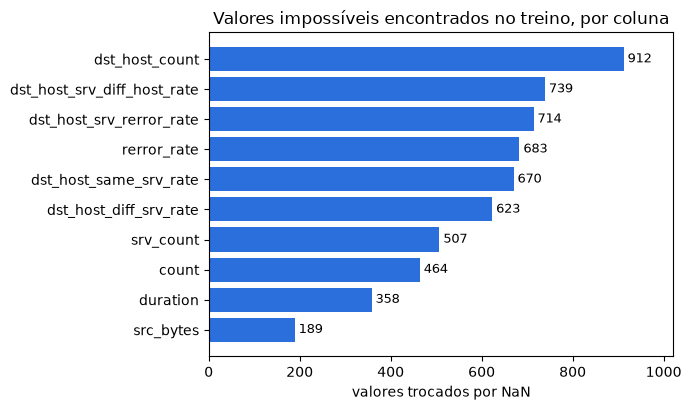

In [4]:
# gráfico 1: onde estavam os valores impossíveis (só o treino tem)
dados = passo2["treino"].iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.2))
ax.barh(dados.index, dados.values, color=AZUL)
for i, v in enumerate(dados.values):   # escreve o número no fim de cada barra
    ax.text(v, i, f" {v}", va="center", fontsize=9)
ax.set_xlim(0, dados.max() * 1.12)
ax.set_xlabel("valores trocados por NaN")
ax.set_title("Valores impossíveis encontrados no treino, por coluna")
plt.tight_layout(); plt.show()

**Conclusão do passo 2**

- 5.859 valores do treino viraram `NaN`, em 5.650 linhas. O teste não tem nenhum valor impossível (os 18 que a Etapa 1 achou no teste eram todos do `su_attempted`, tratado no passo 3).
- Os maiores grupos são `dst_host_count` (912) e as taxas acima de 1, entre 623 e 739 em cada uma das cinco.
- Esses `NaN` se somam aos que já existiam, então o pipeline vai ter mais ausentes para imputar do que a Etapa 1 mostrou.

## 3. `su_attempted = 2` vira 1

Essa coluna deveria ser só 0 ou 1. O valor 2 aparece no treino e no teste, na mesma proporção (a Etapa 1 viu cerca de 0,07% nos dois), então não parece erro colocado só no treino. Tratei como "houve tentativa" e juntei com o 1.

In [5]:
tr3 = L.corrigir_su_attempted(tr2)
te3 = L.corrigir_su_attempted(te2)

print("treino antes:", treino["su_attempted"].value_counts(dropna=False).sort_index().to_dict())
print("treino depois:", tr3["su_attempted"].value_counts(dropna=False).sort_index().to_dict())
print("teste antes:", teste["su_attempted"].value_counts(dropna=False).sort_index().to_dict())
print("teste depois:", te3["su_attempted"].value_counts(dropna=False).sort_index().to_dict())

treino antes: {0.0: 66462, 1.0: 16, 2.0: 49, nan: 3306}
treino depois: {0.0: 66462, 1.0: 65, nan: 3306}
teste antes: {0.0: 23123, 1.0: 9, 2.0: 18, nan: 1183}
teste depois: {0.0: 23123, 1.0: 27, nan: 1183}


**Conclusão do passo 3**

- 49 linhas do treino e 18 do teste tinham `su_attempted = 2`. Agora a coluna só tem 0, 1 ou ausente nas duas bases (os ausentes não foram mexidos).

## 4. Remover colunas

Saem 8 colunas, todas por motivos que a Etapa 1 mostrou:

- **cópias** de colunas que já existem: `src_bytes_kb`, `dst_bytes_kb`, `total_bytes`, `same_srv_pct` e `protocolo_cod`;
- **constante**: `num_outbound_cmds` (um valor só, não ajuda em nada);
- **vazamento**: `tempo_resposta_analista_min` e `tipo_alerta_soc`, que só existem depois que um analista olha a conexão e entregam a classe.

> **Aviso para o grupo:** `score_ids_legado` foi **mantida**. Não sabemos de onde vem essa nota (se vem de um sistema em tempo real ou se foi gerada depois), então o grupo ainda vai decidir se usa. Quem for modelar deve testar com e sem ela.

In [6]:
tr4 = L.remover_colunas(tr3)
te4 = L.remover_colunas(te3)

print("colunas removidas:", L.REMOVER)
print(f"treino: {tr3.shape[1]} -> {tr4.shape[1]} colunas | teste: {te3.shape[1]} -> {te4.shape[1]} colunas")
print("score_ids_legado continua na base:", "score_ids_legado" in tr4.columns and "score_ids_legado" in te4.columns)

colunas removidas: ['src_bytes_kb', 'dst_bytes_kb', 'total_bytes', 'same_srv_pct', 'protocolo_cod', 'num_outbound_cmds', 'tempo_resposta_analista_min', 'tipo_alerta_soc']
treino: 50 -> 42 colunas | teste: 50 -> 42 colunas
score_ids_legado continua na base: True


**Conclusão do passo 4**

- Cada base ficou com 42 colunas: o treino com `class` e o teste com `id`, e as outras 41 iguais nos dois.

## 5. Duplicatas e linhas contraditórias (só no treino)

Esse passo só vale para o treino, depois dos passos anteriores e **nesta ordem**:

1. tiro as linhas exatamente iguais (mesmos atributos e mesma classe), ficando com uma cópia de cada;
2. depois, o que sobrar de linhas com atributos idênticos e classes diferentes eu tiro **inteiro**: não dá para saber qual rótulo está certo, então nenhuma das linhas do grupo fica.

Se a ordem fosse a contrária, as cópias de uma mesma linha contariam como "classes iguais" e o grupo poderia passar despercebido ou ser contado errado. Também não faço isso no teste, porque lá não se pode perder linha.

In [7]:
n0 = len(tr4)
anom0 = (tr4[ALVO] == "anomaly").mean() * 100

tr5a = L.remover_duplicatas(tr4)
n1 = len(tr5a)
anom1 = (tr5a[ALVO] == "anomaly").mean() * 100

tr5 = L.remover_contraditorias(tr5a)
n2 = len(tr5)
anom2 = (tr5[ALVO] == "anomaly").mean() * 100

# quantos grupos contraditórios foram tirados (só pra mostrar; a função já fez o trabalho)
atrib = [c for c in tr5a.columns if c != ALVO]
tam_grupo = tr5a.groupby(atrib, dropna=False)[ALVO].transform("size")
n_grupos = tr5a[tam_grupo > 1].groupby(atrib, dropna=False).ngroups

etapas = pd.DataFrame({
    "linhas": [n0, n1, n2],
    "anomalias": [(tr4[ALVO] == "anomaly").sum(), (tr5a[ALVO] == "anomaly").sum(), (tr5[ALVO] == "anomaly").sum()],
    "% anomalias": [anom0, anom1, anom2],
}, index=["antes", "sem duplicatas exatas", "sem grupos contraditórios"])
etapas["normais"] = etapas["linhas"] - etapas["anomalias"]
display(etapas[["linhas", "normais", "anomalias", "% anomalias"]].round(2))

print(f"Duplicatas removidas: {n0 - n1}")
print(f"Linhas contraditórias removidas: {n1 - n2} (em {n_grupos} grupos)")
print(f"Proporção de anomalias: {anom0:.2f}% -> {anom2:.2f}%")

,linhas,normais,anomalias,% anomalias
antes,69833,65754,4079,5.84
sem duplicatas exatas,58478,54959,3519,6.02
sem grupos contraditórios,55074,53257,1817,3.30


Duplicatas removidas: 11355
Linhas contraditórias removidas: 3404 (em 1702 grupos)
Proporção de anomalias: 5.84% -> 3.30%


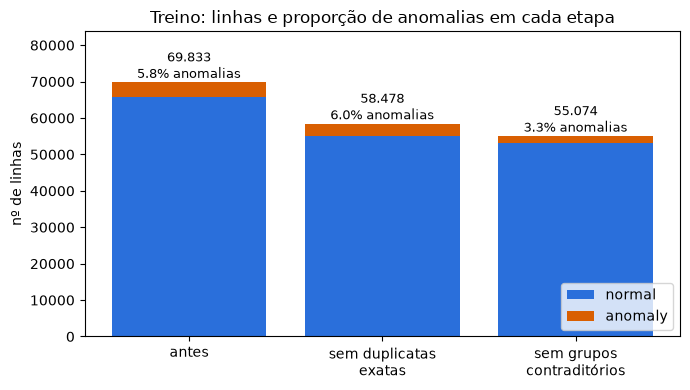

In [8]:
# gráfico 2: linhas do treino em cada etapa, com a % de anomalias
fig, ax = plt.subplots(figsize=(7, 4))
x = np.arange(3)
ax.bar(x, etapas["normais"], color=AZUL, label="normal")
ax.bar(x, etapas["anomalias"], bottom=etapas["normais"], color=LARANJA, label="anomaly")
for i, (n, p) in enumerate(zip(etapas["linhas"], etapas["% anomalias"])):
    ax.text(i, n, f"{n:,}\n{p:.1f}% anomalias".replace(",", "."), ha="center", va="bottom", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(["antes", "sem duplicatas\nexatas", "sem grupos\ncontraditórios"])
ax.set_ylim(0, etapas["linhas"].max() * 1.2)
ax.set_ylabel("nº de linhas")
ax.set_title("Treino: linhas e proporção de anomalias em cada etapa")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

**Conclusão do passo 5**

- Saíram 11.355 duplicatas exatas (o treino foi de 69.833 para 58.478 linhas). A proporção de anomalias subiu de 5,84% para 6,02%.
- Depois saíram 3.404 linhas de 1.702 grupos contraditórios, o que deixa o treino com 55.074 linhas.
- **Atenção:** cada grupo tinha exatamente uma linha normal e uma anomalia. Então saíram 1.702 de cada classe, e as anomalias caíram de 3.519 para 1.817. A proporção final de anomalias é de **3,30%** (cerca de 29 normais para cada anomalia), bem mais desbalanceado do que os 5,8% originais. O grupo precisa saber disso ao escolher o balanceamento.

## 6. O teste

O teste passa só pelos passos 1 a 4 e **nunca perde linha**. A coluna `id` fica, porque é ela que identifica cada linha na submissão. Abaixo aplico a função completa `limpar()` nos dois arquivos e confiro se o resultado é igual ao que fiz passo a passo.

In [9]:
# a função completa, do jeito que o grupo vai usar
treino_limpo = L.limpar(treino, eh_treino=True)
teste_limpo = L.limpar(teste, eh_treino=False)

# tem que dar exatamente o mesmo que o passo a passo
print("treino igual ao passo a passo:", treino_limpo.equals(tr5))
print("teste igual ao passo a passo:", teste_limpo.equals(te4))
print("treino_limpo:", treino_limpo.shape, "| teste_limpo:", teste_limpo.shape)

treino igual ao passo a passo: True
teste igual ao passo a passo: True
treino_limpo: (55074, 42) | teste_limpo: (24333, 42)


## 7. Salvando e conferindo

Salvo os dois arquivos limpos em `BANCO_DE_DADOS/`. Depois **leio de volta os CSVs** e faço as conferências em cima deles, que é o que o grupo vai usar de verdade: linhas do teste, valores impossíveis, colunas do treino e do teste, `id` e duplicatas.

In [10]:
treino_limpo.to_csv(PASTA / "treino_limpo.csv", index=False)
teste_limpo.to_csv(PASTA / "teste_limpo.csv", index=False)

# leitura de volta, pra conferir os arquivos e não só a memória
tr_f = pd.read_csv(PASTA / "treino_limpo.csv")
te_f = pd.read_csv(PASTA / "teste_limpo.csv")

# conta valores impossíveis com as regras escritas de novo aqui (sem usar o limpeza.py)
def impossiveis(df):
    taxas = [c for c in df.columns if c.endswith("_rate")]
    out = {}
    for c in ["duration", "src_bytes", "dst_bytes"]:
        out[f"{c} < 0"] = (df[c] < 0).sum()
    out["*_rate > 1"] = (df[taxas] > 1).sum().sum()
    out["count ou srv_count > 511"] = (df[["count", "srv_count"]] > 511).sum().sum()
    out["dst_host_count ou dst_host_srv_count > 255"] = (df[["dst_host_count", "dst_host_srv_count"]] > 255).sum().sum()
    out["su_attempted fora de {0, 1}"] = (df["su_attempted"].notna() & ~df["su_attempted"].isin([0, 1])).sum()
    return pd.Series(out)

imp = pd.DataFrame({"treino_limpo": impossiveis(tr_f), "teste_limpo": impossiveis(te_f)})
display(imp)

cols_tr = [c for c in tr_f.columns if c != ALVO]
cols_te = [c for c in te_f.columns if c != "id"]
atributos = tr_f.drop(columns=ALVO)
# linhas com atributos iguais, mas qualquer classe (se não sobrou duplicata exata, seriam contraditórias)
iguais = atributos.duplicated(keep=False)

def texto_ok(df):
    ok = True
    for c in L.TEXTO_MINUSCULA:
        ok &= (df[c].dropna() == df[c].dropna().str.strip().str.lower()).all()
    for c in L.TEXTO_MAIUSCULA:
        ok &= (df[c].dropna() == df[c].dropna().str.strip().str.upper()).all()
    return bool(ok)

conferencias = {
    "teste com 24.333 linhas": len(te_f) == 24333,
    "teste com as mesmas linhas, na mesma ordem (id igual ao original)": te_f["id"].equals(teste["id"]),
    "nenhum valor impossível (treino e teste)": int(imp.to_numpy().sum()) == 0,
    "colunas do treino = colunas do teste (fora class e id)": cols_tr == cols_te,
    "class só no treino e id só no teste": ALVO in tr_f.columns and ALVO not in te_f.columns and "id" in te_f.columns and "id" not in tr_f.columns,
    "treino sem duplicatas exatas": not tr_f.duplicated().any(),
    "treino sem linhas iguais (nem com classes diferentes)": not iguais.any(),
    "nenhuma coluna removida sobrou": not set(L.REMOVER) & (set(tr_f.columns) | set(te_f.columns)),
    "score_ids_legado mantida": "score_ids_legado" in tr_f.columns and "score_ids_legado" in te_f.columns,
    "texto padronizado (treino e teste)": texto_ok(tr_f) and texto_ok(te_f),
}
for nome, ok in conferencias.items():
    print("OK  " if ok else "ERRO", nome)
assert all(conferencias.values()), "alguma conferência falhou"

print(f"\ncolunas do treino ({tr_f.shape[1]}):", list(tr_f.columns))

,treino_limpo,teste_limpo
duration < 0,0,0
src_bytes < 0,0,0
dst_bytes < 0,0,0
*_rate > 1,0,0
count ou srv_count > 511,0,0
dst_host_count ou dst_host_srv_count > 255,0,0
"su_attempted fora de {0, 1}",0,0


OK   teste com 24.333 linhas
OK   teste com as mesmas linhas, na mesma ordem (id igual ao original)
OK   nenhum valor impossível (treino e teste)
OK   colunas do treino = colunas do teste (fora class e id)
OK   class só no treino e id só no teste
OK   treino sem duplicatas exatas
OK   treino sem linhas iguais (nem com classes diferentes)
OK   nenhuma coluna removida sobrou
OK   score_ids_legado mantida
OK   texto padronizado (treino e teste)

colunas do treino (42): ['duration', 'protocol_type', 'service', 'flag', 'src_bytes', 'dst_bytes', 'land', 'wrong_fragment', 'urgent', 'hot', 'num_failed_logins', 'logged_in', 'num_compromised', 'root_shell', 'su_attempted', 'num_root', 'num_file_creations', 'num_shells', 'num_access_files', 'is_host_login', 'is_guest_login', 'count', 'srv_count', 'serror_rate', 'srv_serror_rate', 'rerror_rate', 'srv_rerror_rate', 'same_srv_rate', 'diff_srv_rate', 'srv_diff_host_rate', 'dst_host_count', 'dst_host_srv_count', 'dst_host_same_srv_rate', 'dst_host_dif

**Conclusão do passo 7**

- O teste tem as mesmas 24.333 linhas, com o `id` igual ao original e na mesma ordem.
- Não sobrou nenhum valor impossível no treino nem no teste.
- As 41 colunas de atributos são iguais nos dois arquivos, na mesma ordem. Sobrou também uma coluna de cada lado: `class` no treino e `id` no teste.
- O treino não tem mais nenhuma linha repetida.

## 8. Diagnóstico final

Resumo de tudo que foi feito, quantas linhas ou colunas cada passo afetou e o motivo. Os números saem das variáveis do notebook, não foram digitados.

In [11]:
fmt = lambda n: f"{int(n):,}".replace(",", ".")

# números de cada passo (cada um calculado nas células acima)
diag = pd.DataFrame([
    ["1. Padronizar texto (strip + minúsculas/maiúsculas)",
     f"{fmt(m_tr.any(axis=1).sum())} linhas", f"{fmt(m_te.any(axis=1).sum())} linhas",
     "O mesmo valor aparecia com grafias diferentes (TCP, espaço no final do service) e viraria categorias separadas."],
    ["2. Valores impossíveis -> NaN",
     f"{fmt(lin_tr)} linhas ({fmt(passo2['treino'].sum())} valores)", f"{fmt(lin_te)} linhas ({fmt(passo2['teste'].sum())} valores)",
     "Negativos e fora dos limites não existem pela definição dos atributos. Viram ausentes para o pipeline imputar."],
    ["3. su_attempted 2 -> 1",
     f"{fmt((tr2['su_attempted'] == 2).sum())} linhas", f"{fmt((te2['su_attempted'] == 2).sum())} linhas",
     "A coluna só deveria ter 0 ou 1; o 2 aparece nas duas bases na mesma proporção."],
    ["4. Remover colunas (cópias, constante, vazamento)",
     f"{len(L.REMOVER)} colunas", f"{len(L.REMOVER)} colunas",
     "Cópias e constante não acrescentam informação; as duas de vazamento só existem depois de um analista olhar a conexão. score_ids_legado foi mantida (grupo decide)."],
    ["5a. Remover duplicatas exatas (só treino)",
     f"{fmt(n0 - n1)} linhas", "0 (não se aplica)",
     "A mesma linha no treino e na validação deixa o resultado otimista; as cópias também tinham mais anomalias que o resto."],
    ["5b. Remover grupos contraditórios (só treino)",
     f"{fmt(n1 - n2)} linhas ({fmt(n_grupos)} grupos)", "0 (não se aplica)",
     "Atributos idênticos com classes diferentes são ruído de rótulo: nenhum modelo acerta os dois."],
    ["Resultado final",
     f"{fmt(len(treino))} -> {fmt(len(tr_f))} linhas; {treino.shape[1]} -> {tr_f.shape[1]} colunas; anomalias {(treino[ALVO] == 'anomaly').mean() * 100:.1f}% -> {(tr_f[ALVO] == 'anomaly').mean() * 100:.1f}%",
     f"{fmt(len(teste))} -> {fmt(len(te_f))} linhas (nenhuma perdida); {teste.shape[1]} -> {te_f.shape[1]} colunas",
     "Base comum para o grupo. Ainda faltam: imputar, codificar e normalizar (dentro do pipeline)."],
], columns=["o que foi feito", "treino", "teste", "por quê"])

with pd.option_context("display.max_colwidth", 200):
    display(diag.style.hide(axis="index").set_properties(**{"text-align": "left", "white-space": "normal"}))

o que foi feito,treino,teste,por quê
1. Padronizar texto (strip + minúsculas/maiúsculas),4.235 linhas,100 linhas,"O mesmo valor aparecia com grafias diferentes (TCP, espaço no final do service) e viraria categorias separadas."
2. Valores impossíveis -> NaN,5.650 linhas (5.859 valores),0 linhas (0 valores),Negativos e fora dos limites não existem pela definição dos atributos. Viram ausentes para o pipeline imputar.
3. su_attempted 2 -> 1,49 linhas,18 linhas,A coluna só deveria ter 0 ou 1; o 2 aparece nas duas bases na mesma proporção.
"4. Remover colunas (cópias, constante, vazamento)",8 colunas,8 colunas,Cópias e constante não acrescentam informação; as duas de vazamento só existem depois de um analista olhar a conexão. score_ids_legado foi mantida (grupo decide).
5a. Remover duplicatas exatas (só treino),11.355 linhas,0 (não se aplica),A mesma linha no treino e na validação deixa o resultado otimista; as cópias também tinham mais anomalias que o resto.
5b. Remover grupos contraditórios (só treino),3.404 linhas (1.702 grupos),0 (não se aplica),Atributos idênticos com classes diferentes são ruído de rótulo: nenhum modelo acerta os dois.
Resultado final,69.833 -> 55.074 linhas; 50 -> 42 colunas; anomalias 5.8% -> 3.3%,24.333 -> 24.333 linhas (nenhuma perdida); 50 -> 42 colunas,"Base comum para o grupo. Ainda faltam: imputar, codificar e normalizar (dentro do pipeline)."


**Para quem for usar:** `from limpeza import limpar` e depois `limpar(df, eh_treino=True)` para o treino ou `limpar(df, eh_treino=False)` para o teste, ou então ler direto `treino_limpo.csv` e `teste_limpo.csv`. A base ainda tem ausentes, textos e escalas diferentes: imputar, codificar e normalizar entram no pipeline de cada um, ajustando só com o treino de cada fold. E lembrem que `score_ids_legado` ainda está em aberto.